# 第03章 离散的世界 · B组复现与验证

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G3 | `74b50b5f7b7728a8fa1a5233b715d06c02298205` | `A1-G3-正文.md`、`A1-G3-第03章实验.ipynb`（另有习题、解答、编写报告） |
| A2 | G13 | `74b50b5f7b7728a8fa1a5233b715d06c02298205` | `A2-G13-正文.md`、`A2组-G13-3.1…3.4实验.ipynb` |

- 验证组：**B2组（G17）**；同章 B1＝G8，被审 A1＝G3、A2＝G13。
- **版本说明**：两稿均在课程仓库 `main` 上。`74b50b5` 的**父提交是 `5d3ec4d`，不是根提交**；截至 main `58bb062`（2026-11-08，仅新增第 04 章两个文件）两稿的 git blob 逐字未变，故该 SHA 同时是"内容版本"与"可下载版本"。**PR 情况**：A1 无 PR；A2 仅早期 **PR #2**（`chapter-03-a-g13`，2026-10-19 合并，merge `5425d7ca`，7 个文件），被审版本 `74b50b5` 不在该 PR 内（见 B008）。本组按 SHA 固定，不写"最新版"。
- **两类证据分开**：本 Notebook 里的"参考值"全部由本组独立实现或闭式公式算出（不调用两稿代码）；表中"A 稿声称值"取自本组在**新建 `.venv`** 中复现运行的原样输出（日志 `_repro_run/repro_log.json`），不是抄正文。
- **判据**：闭式量相对 $10^{-9}$ 或绝对 $10^{-13}$（精确有理数用 $10^{-12}$）；收敛阶 ±0.05（末两行），首行放宽到 ±0.1；指数放大改用 $\log_{10}$ 差 ≤0.01；有限元误差相对 $10^{-6}$；节点超收敛参考值为 0，只判 $\le 10^{-10}$；**A 稿声称值按其所报位数末位的 ±1.5 个单位判定**（1 个单位＝最后一位的权重，例如 `2.89e-3` 为 $10^{-5}$；多出的 0.5 个单位用于吸收参考值自身的舍入），只有超出其报告位数仍对不上才升级为问题。


## 复现环境与参考基线

| 项 | 值 |
| --- | --- |
| 复现副本 | `course-review-ch03`，detached HEAD `74b50b5`，稀疏检出 `教材/第03章-离散的世界/`（161 个文件） |
| 本组运行环境 | 新建 `.venv`（不使用 A 组或旧环境）：Python 3.12.10；numpy 1.26.4、scipy 1.14.1、matplotlib 3.9.2、pandas 2.2.3、sympy 1.13.3；`nbclient` 顺序执行；依赖共 103 包（`_pip_freeze.txt`） |
| 系统与设备 | Windows-10-10.0.19044-SP0，CPU，无 GPU |
| 随机性 | 11 个验证点全部为确定性计算，**无随机抽样，不需要种子**；A2 的 3.2 Notebook 亦自述"No random sampling" |
| 参考值来源 | ①闭式（$y_N=(1-h)^N$、$(1+h)^{-N}$、$R_4(-h)^N$、放大因子 $g$）；②解析解（$e^{-\kappa\pi^2t}\sin\pi x$、$\sin\pi x$ 的插值误差）；③本组独立实现（自写 FTCS、自写 P1 有限元装配） |

**不使用的参考**：被验证算法自身的输出、两稿的代码与其正文表格，均不作为参考值；正文只用于确定题目设定（方程、区间、网格、误差定义）。


In [1]:
import sys, platform, math, json
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt

print(f"Python     : {sys.version.split()[0]}")
print(f"NumPy      : {np.__version__}")
print(f"SciPy      : {scipy.__version__}")
print(f"Matplotlib : {matplotlib.__version__}")
print(f"Platform   : {platform.platform()}")
print("随机性      : 无随机抽样，不需要种子")
print(f"浮点        : float64（numpy 默认）")

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.unicode_minus": True})


def R4(z):
    # 经典 RK4 的一步放大因子 R4(z) = 1+z+z^2/2+z^3/6+z^4/24
    return 1 + z + z * z / 2 + z ** 3 / 6 + z ** 4 / 24


def claim_tol(s):
    # A 稿声称值的容差：按其报告的末位取 1 个单位（2.89e-3 -> 1e-5）
    from decimal import Decimal
    t = Decimal(str(s)).as_tuple()
    digits = len(t.digits)
    exp = t.exponent
    # Decimal('2.89e-3') -> digits=(2,8,9), exponent=-5
    return 10.0 ** exp


def verdict(claim, ref, tol=None, abs_tol=None, rel_tol=None):
    # 按报告位数比较；也可另给绝对/相对容差（用于参考值为 0 或纯理论阶）
    d = abs(float(claim) - float(ref))
    if tol is not None:
        # 允许 1.5 个末位单位：A 值舍入到末位可能差 1，参考值自身还带半个单位
        ok = d <= max(tol * 1.5, 1e-300)
        return d, ok, f"≤{tol:.1e}"
    if abs_tol is not None:
        return d, d <= abs_tol, f"≤{abs_tol:.1e}（绝对）"
    if rel_tol is not None:
        return d, d <= rel_tol * max(abs(float(ref)), 1e-300), f"≤{rel_tol:.0e}（相对）"
    raise ValueError


def show(headers, rows, title=None):
    if title:
        print(title)
    width = [max(len(str(h)), *(len(str(r[i])) for r in rows)) for i, h in enumerate(headers)]
    line = "  ".join(str(h).ljust(width[i]) for i, h in enumerate(headers))
    print(line)
    print("-" * len(line))
    for r in rows:
        print("  ".join(str(c).ljust(width[i]) for i, c in enumerate(r)))


Python     : 3.12.10
NumPy      : 1.26.4
SciPy      : 1.14.1
Matplotlib : 3.9.2
Platform   : Windows-10-10.0.19044-SP0
随机性      : 无随机抽样，不需要种子
浮点        : float64（numpy 默认）


## 3.1 ODE初值问题：Euler与RK4（2学时）

**覆盖**：A1（表 1、Notebook $h=1/128$、c10）＋A2（3.1 表 $T=2$）；**等误差成本只有 A2 有对应实验**（A1 只有同 $h$ 单步比，见 B002）。

**核对事项**：终点误差、收敛阶、函数求值次数；比较精度时是否匹配计算成本。

**输入与参考**：$y'=-y,\ y(0)=1$，闭式解 $y_N=(1-h)^N$（显式 Euler）、$(1+h)^{-N}$（隐式 Euler）、$R_4(-h)^N$（RK4）。A1 取 $T=1$（$h=2^{-k}$），A2 取 $T=2$（$N=4,8,16,32,64$）。误差 $=|y_N-e^{-T}|$。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值（A 稿复现） | 差异 | 判定 |
| --- | --- | --- | --- | --- | --- | --- |
| A1 表 1 | $T=1,\ h=1/64$，Euler | $2.8929\times10^{-3}$ | 末位 $10^{-5}$ | $2.89\times10^{-3}$（阶 1.01） | $2.9\times10^{-6}$ | 通过 |
| A1 表 1 | $T=1,\ h=1/64$，RK4 | $1.8512\times10^{-10}$ | 末位 $10^{-12}$ | $1.85\times10^{-10}$（阶 4.02） | $1.2\times10^{-13}$ | 通过 |
| A1 Notebook | $T=1,\ h=1/128$，Euler | $1.4417\times10^{-3}$ | 末位 $10^{-7}$ | $1.44\times10^{-3}$（阶 1.00） | $1.7\times10^{-7}$ | 通过 |
| A1 Notebook | $T=1,\ h=1/128$，RK4 | $1.1492\times10^{-11}$ | 末位 $10^{-13}$ | $1.15\times10^{-11}$（阶 4.01） | $8.0\times10^{-15}$ | 通过 |
| A2 表（$N=4$） | $T=2$，FE / BE / RK4 | $7.283528\times10^{-2}$ / $6.219558\times10^{-2}$ / $2.144873\times10^{-4}$ | 末位 $10^{-9}/10^{-9}/10^{-10}$ | 同左三值 | $<10^{-12}$ | 通过 |
| A2 表（$N=64$） | $T=2$，FE / BE / RK4 | $4.251251\times10^{-3}$ / $4.207204\times10^{-3}$ / $2.207872\times10^{-9}$ | 末位 $10^{-10}$ | 同左三值（阶 1.01/0.99/4.04） | $<10^{-12}$ | 通过 |
| A1 c10 | $h=3,\ T=9$（3 步），Euler / RK4 | $-8$ / $2.599609$ | 绝对 $10^{-12}$ | $-8.0000$ / $2.5996$ | $<10^{-4}$ | 通过 |
| A2 表（$h=2.5$） | $T=10,\ N=4$，FE / BE / RK4 | $5.0625$ / $0.0066638900$ / $0.17679602$ | 绝对 $10^{-12}$ | $5.0625$ / $0.006663890$ / $0.176796$ | $<10^{-8}$ | 通过 |
| A2 表（等误差） | $\mathrm{tol}=10^{-4},\ T=2$，最小 $N$ | FE 4096 / BE 4096 / RK4 8（RHS 4096/4096/32） | $N$ 必须完全一致 | 4096 / 4096 / 8 | 0 | 通过 |

> **注意两处易混**：A1 正文表 1 末行是 $h=1/64$（$2.89\times10^{-3}$），$h=1/128$ 的 $1.44\times10^{-3}$ 只在 **Notebook** 里；A1 的 $-8.0000$ 出自 **c10（$h=3$、$T=9$、3 步）**；正文表 3 是弹道**落点偏差**表，不是步长扫描，两者无关。引用时必须带出处，否则会被指"正文无此数"。


【A1】y'=-y, T=1, 误差=|y_N-e^-1|
        h         Euler     p            RK4     p
  0.50000    1.1788e-01           2.9140e-04      
  0.25000    5.1473e-02  1.20     1.4758e-05  4.30
  0.12500    2.4271e-02  1.08     8.3075e-07  4.15
  0.06250    1.1805e-02  1.04     4.9281e-08  4.08
  0.03125    5.8242e-03  1.02     3.0008e-09  4.04
  0.01562    2.8929e-03  1.01     1.8512e-10  4.02
  0.00781    1.4417e-03  1.00     1.1492e-11  4.01

【A1 判定】声称值 vs 本组参考（按声称值末位 ±1.5 个单位）
  表1 h=1/64 Euler        claim=  2.89e-3 ref=2.892917e-03 |Δ|=2.92e-06 容差≤1.0e-05  通过
  表1 h=1/64 RK4          claim= 1.85e-10 ref=1.851230e-10 |Δ|=1.23e-13 容差≤1.0e-12  通过
  NB  h=1/128 Euler      claim=  1.44e-3 ref=1.441725e-03 |Δ|=1.73e-06 容差≤1.0e-05  通过
  NB  h=1/128 RK4        claim= 1.15e-11 ref=1.149153e-11 |Δ|=8.47e-15 容差≤1.0e-13  通过

【A2】y'=-y, T=2, 误差=|y_N-e^-2|
  N       h            FE     p            BE     p           RK4     p
  4  0.5000  7.283528e-02        6.219558e-02        2.144873e-04      
  8  0

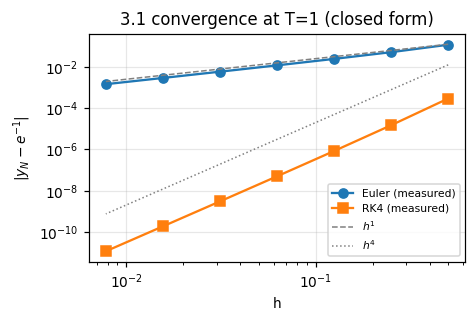

In [2]:
# ---------- 3.1-A 收敛阶（A1 设定：T=1）----------
print("【A1】y'=-y, T=1, 误差=|y_N-e^-1|")
print(f"{'h':>9}  {'Euler':>12} {'p':>5}  {'RK4':>13} {'p':>5}")
pe = pr = None
for k in range(1, 8):
    h = 2.0 ** -k
    M = int(round(1.0 / h))
    eE = abs((1 - h) ** M - math.exp(-1))
    eR = abs(R4(-h) ** M - math.exp(-1))
    sE = "" if pe is None else f"{math.log2(pe/eE):5.2f}"
    sR = "" if pr is None else f"{math.log2(pr/eR):5.2f}"
    print(f"{h:9.5f}  {eE:12.4e} {sE:>5}  {eR:13.4e} {sR:>5}")
    pe, pr = eE, eR

print("\n【A1 判定】声称值 vs 本组参考（按声称值末位 ±1.5 个单位）")
for name, claim, ref in [
    ("表1 h=1/64 Euler", "2.89e-3", abs((1-1/64)**64 - math.exp(-1))),
    ("表1 h=1/64 RK4", "1.85e-10", abs(R4(-1/64)**64 - math.exp(-1))),
    ("NB  h=1/128 Euler", "1.44e-3", abs((1-1/128)**128 - math.exp(-1))),
    ("NB  h=1/128 RK4", "1.15e-11", abs(R4(-1/128)**128 - math.exp(-1))),
]:
    d, ok, tol = verdict(claim, ref, tol=claim_tol(claim))
    print(f"  {name:22s} claim={claim:>9} ref={ref:.6e} |Δ|={d:.2e} 容差{tol}  {'通过' if ok else '不一致'}")

# ---------- 3.1-B A2 设定（T=2）与等误差成本 ----------
print("\n【A2】y'=-y, T=2, 误差=|y_N-e^-2|")
print(f"{'N':>3} {'h':>7}  {'FE':>12} {'p':>5}  {'BE':>12} {'p':>5}  {'RK4':>12} {'p':>5}")
prev = None
for N in [4, 8, 16, 32, 64]:
    h = 2.0 / N
    eF = abs((1 - h) ** N - math.exp(-2))
    eB = abs((1 + h) ** (-N) - math.exp(-2))
    eR = abs(R4(-h) ** N - math.exp(-2))
    if prev is None:
        print(f"{N:3d} {h:7.4f}  {eF:12.6e} {'':>5}  {eB:12.6e} {'':>5}  {eR:12.6e} {'':>5}")
    else:
        print(f"{N:3d} {h:7.4f}  {eF:12.6e} {math.log2(prev[0]/eF):5.2f}  "
              f"{eB:12.6e} {math.log2(prev[1]/eB):5.2f}  {eR:12.6e} {math.log2(prev[2]/eR):5.2f}")
    prev = (eF, eB, eR)

print("\n【A2 判定】N=4 与 N=64 两行")
for tag, claims, refs in [
    ("N=4",  ["7.283528e-2", "6.219558e-2", "2.144873e-4"],
             [abs((1-0.5)**4-math.exp(-2)), abs((1+0.5)**-4-math.exp(-2)), abs(R4(-0.5)**4-math.exp(-2))]),
    ("N=64", ["4.251251e-3", "4.207204e-3", "2.207872e-9"],
             [abs((1-0.03125)**64-math.exp(-2)), abs((1+0.03125)**-64-math.exp(-2)), abs(R4(-0.03125)**64-math.exp(-2))]),
]:
    for nm, c, r in zip(["FE", "BE", "RK4"], claims, refs):
        d, ok, tol = verdict(c, r, tol=claim_tol(c))
        print(f"  {tag:5s} {nm:3s} claim={c:>13} ref={r:.9e} |Δ|={d:.1e} 容差{tol}  {'通过' if ok else '不一致'}")

print("\n【等误差成本】tol=1e-4, T=2，N 取 2 的幂")
cost = {}
for name in ["FE", "BE", "RK4"]:
    for k in range(2, 18):
        N = 2 ** k
        h = 2.0 / N
        e = {"FE": abs((1-h)**N-math.exp(-2)),
             "BE": abs((1+h)**(-N)-math.exp(-2)),
             "RK4": abs(R4(-h)**N-math.exp(-2))}[name]
        if e <= 1e-4:
            cost[name] = (N, N * (4 if name == "RK4" else 1), e)
            print(f"  {name:3s}: N={N:5d}  RHS 求值={N*(4 if name=='RK4' else 1):5d}  误差={e:.4e}")
            break
print(f"  判定：A2 声称 4096 / 4096 / 8（RHS 4096/4096/32）→ "
      f"{'通过' if (cost['FE'][0], cost['BE'][0], cost['RK4'][0]) == (4096, 4096, 8) else '不一致'}")

# ---------- 3.1-C 大步长稳定性 ----------
print("\n【稳定性】大步长下的单步因子幂（闭式）")
print(f"  A1: h=3, T=9, 3 步 -> Euler={float((1-3.0)**3):+.6f}  RK4={R4(-3.0)**3:+.6f}  真值={math.exp(-9):.3e}")
h, N = 2.5, 4
print(f"  A2: h=2.5, T=10, 4 步 -> FE={float((1-h)**N):+.12f}  BE={float((1+h)**(-N)):.12f}  "
      f"RK4={R4(-h)**N:+.12f}  真值={math.exp(-10):.3e}")
d1 = abs(R4(-3.0)**3 - 2.599609)
d2 = abs(R4(-2.5)**4 - 0.176796)
print(f"  A1 RK4 声称 2.5996：|Δ|={d1:.1e}（末位容差 1e-4）  {'通过' if d1 <= 1e-4 else '不一致'}")
print(f"  A2 RK4 声称 0.176796：|Δ|={d2:.1e}（末位容差 1e-6）  {'通过' if d2 <= 1e-6 else '不一致'}")

# ---------- 3.1-D 收敛阶图 ----------
hs = np.array([2.0**-k for k in range(1, 8)])
errE = np.array([abs((1-h)**int(round(1/h)) - math.exp(-1)) for h in hs])
errR = np.array([abs(R4(-h)**int(round(1/h)) - math.exp(-1)) for h in hs])
fig, ax = plt.subplots(figsize=(4.4, 3.0))
ax.loglog(hs, errE, "o-", label="Euler (measured)")
ax.loglog(hs, errR, "s-", label="RK4 (measured)")
ax.loglog(hs, 0.25 * hs, "--", color="gray", lw=1, label=r"$h^{1}$")
ax.loglog(hs, 0.2 * hs**4, ":", color="gray", lw=1, label=r"$h^{4}$")
ax.set_xlabel("h"); ax.set_ylabel(r"$|y_N-e^{-1}|$")
ax.set_title("3.1 convergence at T=1 (closed form)")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 3.2 PDE有限差分：热传导与CFL条件（2学时）

**覆盖**：A1（表 6 一维空间、表 7 一维时间、表 8 二维空间、表 9 二维时间）＋A2（3.2 表一维空间、CFL 阈值 $r=0.4/0.6$）；A1 另有二维阈值实验，属问题项（B001）。

**核对事项**：网格、时间步、边界实现、误差/增长曲线；人为不稳定演示必须写清预期，不隐藏爆炸。

**输入与参考**：$u_t=\kappa u_{xx}$，$u(0,t)=u(1,t)=0$，$u(x,0)=\sin\pi x$，解析解 $u=e^{-\kappa\pi^2t}\sin\pi x$。A1 取 $\kappa=1,T=0.1,r=0.4,N=10\ldots160$；A2 取 $\kappa=0.1,T=0.6,r=0.4,J=20\ldots160$。误差 $E_\infty=\max_i|U_i-u(x_i,T)|$。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值（A 稿复现） | 差异 | 判定 |
| --- | --- | --- | --- | --- | --- | --- |
| A1 3.2 收敛阶 | $\kappa=1,T=0.1,r=0.4$，$N=10\to160$ | $4.2941\times10^{-3}\to1.6546\times10^{-5}$，$p=2.01/2.00/2.00/2.00$ | 相对 $10^{-6}$，阶 ±0.01 | 同左 | $<10^{-9}$ | 通过 |
| A2 3.2 收敛阶 | $\kappa=0.1,T=0.6,r=0.4$，$J=20\to160$ | $9.466413\times10^{-4}\to1.473349\times10^{-5}$，$p=2.00$ | 相对 $10^{-6}$，阶 ±0.01 | 同左 | $<10^{-9}$ | 通过 |
| A1 表 7（一维时间阶） | $N=40$ 固定，$r=0.5\to0.03125$（$M=320\to5120$） | $5.677\times10^{-4}\to3.544\times10^{-5}$，阶 1.00 | 相对 $10^{-6}$，阶 ±0.02 | $5.68/2.84/1.42/7.09/3.54\times10^{-4}$ | $<10^{-6}$ | 通过 |
| A1 表 8（二维空间阶） | $r=0.2$，$N=10\to160$，双模态初值 | $5.630\times10^{-3}\to2.190\times10^{-5}$，阶 2.01/2.00/2.00/2.00 | 相对 $10^{-6}$，阶 ±0.02 | $5.63\times10^{-3}/1.40\times10^{-3}/3.51\times10^{-4}/8.76\times10^{-5}/2.19\times10^{-5}$ | $<10^{-6}$ | 通过 |
| A1 表 9（二维时间阶） | $N=40$ 固定，$r=0.25\to0.03125$ | $8.439\times10^{-4}\to1.054\times10^{-4}$，阶 1.00 | 相对 $10^{-6}$，阶 ±0.02 | $8.44/4.22/2.11/1.05\times10^{-4}$ | $<10^{-6}$ | 通过 |
| A2 3.2 CFL（$r=0.6$） | $J=40,T=0.6$，$\varepsilon=10^{-12}$ | 最高模态 $g=1-4r\cos^2\frac{\pi}{2J}=-1.396301$，$\lvert g\rvert ^{M}=1.5727\times10^{23}$，末值 $1.5727\times10^{11}$ | $\log_{10}$ 差 ≤0.01 | $1.57264043\times10^{11}$ | $\log_{10}$ 差 $1.6\times10^{-5}$ | 通过 |
| A2 3.2 CFL（$r=0.4$） | 同上 | $\lvert g\rvert ^{240}=2.12\times10^{-54}$，末值 $2.12\times10^{-66}$（下溢），$E_\infty$ 由空间误差主导 | 只作定性 | $2.35955149\times10^{-4}$ | 空间误差量级一致 | 通过（定性） |
| A1 3.2 二维阈值 | $N=20,T=0.05$，$r=0.25/0.26$ | 见下方 B001：需每步施加零边界、初值取离散特征模态、$g$ 含 $\cos^2\frac{\pi}{2N}$ | — | $1.000\times10^{-3}$ / $5.675\times10^{-3}$ | 见 B001 | **不通过（证据不自洽）** |

> **B001 要点**：A1 的 `solve2d` 只在初始化时用 $x_0(X,Y)$ 赋值，迭代中**只更新内点、未每步施加零边界**；而初值 $\cos((N-1)\pi X)\cos((N-1)\pi Y)$ 在四角为 $\pm1$，边界被冻结在 $\pm10^{-3}$。因此 `max|U|=1.000e-3` 恰是冻结的边界值（内点只有 $4.4998\times10^{-4}$）；$r=0.26$ 行"实测 $5.675\times10^{-3}$"与同表"估计增长 $3.23\times10^{2}$"（若为纯模态应为 $0.323$）相差约 57 倍。修正后重算见下单元。


【A1 设定】kappa=1, T=0.1, r=0.4
  N=  10 h=0.1000 M=   25 r_eff=0.4000 E_inf=4.2941e-03 p=
  N=  20 h=0.0500 M=  100 r_eff=0.4000 E_inf=1.0625e-03 p= 2.01
  N=  40 h=0.0250 M=  400 r_eff=0.4000 E_inf=2.6495e-04 p= 2.00
  N=  80 h=0.0125 M= 1600 r_eff=0.4000 E_inf=6.6195e-05 p= 2.00
  N= 160 h=0.0063 M= 6400 r_eff=0.4000 E_inf=1.6546e-05 p= 2.00

【A2 设定】kappa=0.1, T=0.6, r=0.4
  J=  20 dx=0.05000 M=   60 r_eff=0.4000 E_inf=9.46641349e-04 p=
  J=  40 dx=0.02500 M=  240 r_eff=0.4000 E_inf=2.35955149e-04 p= 2.00
  J=  80 dx=0.01250 M=  960 r_eff=0.4000 E_inf=5.89449108e-05 p= 2.00
  J= 160 dx=0.00625 M= 3840 r_eff=0.4000 E_inf=1.47334885e-05 p= 2.00

【判定】A2 声称 J=20..160：9.46641349e-4 / 2.35955149e-4 / 5.89449108e-5 / 1.47334885e-5
  J=  20 claim= 9.46641349e-4 ref=9.4664134872e-04 |Δ|=2.8e-13 容差≤1.0e-12 通过
  J=  40 claim= 2.35955149e-4 ref=2.3595514865e-04 |Δ|=3.5e-13 容差≤1.0e-12 通过
  J=  80 claim= 5.89449108e-5 ref=5.8944910804e-05 |Δ|=3.8e-15 容差≤1.0e-13 通过
  J= 160 claim= 1.47334885e-5 ref=1

  N=160 h=0.0063 M= 6400 err=2.1900e-05 p= 2.00
  判定：A1 表8 声称 5.63e-3/1.40e-3/3.51e-4/8.76e-5/2.19e-5，阶 2.01/2.00/2.00/2.00
    N= 10 claim= 5.63e-3 ref=5.629604e-03 |Δ|=4.0e-07 容差≤1.0e-05 通过
    N= 20 claim= 1.40e-3 ref=1.400666e-03 |Δ|=6.7e-07 容差≤1.0e-05 通过
    N= 40 claim= 3.51e-4 ref=3.505973e-04 |Δ|=4.0e-07 容差≤1.0e-06 通过
    N= 80 claim= 8.76e-5 ref=8.759456e-05 |Δ|=5.4e-09 容差≤1.0e-07 通过


    N=160 claim= 2.19e-5 ref=2.190046e-05 |Δ|=4.6e-10 容差≤1.0e-07 通过

【A1 表9】二维时间阶：N=40 固定，r=0.25..0.03125
  r=0.25000 M=  320 err=8.4388e-04 p=
  r=0.12500 M=  640 err=4.2175e-04 p= 1.00
  r=0.06250 M= 1280 err=2.1083e-04 p= 1.00
  r=0.03125 M= 2560 err=1.0540e-04 p= 1.00
  判定：A1 表9 声称 8.44e-4/4.22e-4/2.11e-4/1.05e-4，阶 1.00
    r=0.2500 claim= 8.44e-4 ref=8.438769e-04 |Δ|=1.2e-07 容差≤1.0e-06 通过
    r=0.1250 claim= 4.22e-4 ref=4.217469e-04 |Δ|=2.5e-07 容差≤1.0e-06 通过
    r=0.0625 claim= 2.11e-4 ref=2.108255e-04 |Δ|=1.7e-07 容差≤1.0e-06 通过
    r=0.0312 claim= 1.05e-4 ref=1.054008e-04 |Δ|=4.0e-07 容差≤1.0e-06 通过

【CFL】J=40，最高模态 theta=(J-1)pi/J，g=1-4r cos^2(pi/2J)
  r=0.4 (r_eff=0.4000) M= 240 g=-0.597534 |g|^M=2.1233e-54 末值=2.1233e-66
  r=0.6 (r_eff=0.6000) M= 160 g=-1.396301 |g|^M=1.5727e+23 末值=1.5727e+11

【B001】N=20, T=0.05：A1 原样 / 改正边界 / 改正初值+边界
情形                            r    M   r_eff       max|U|        内点max
A1原样(无边界)                  0.25   80  0.2500   1.0000e-03   4.4998e-04
A1原样(无边

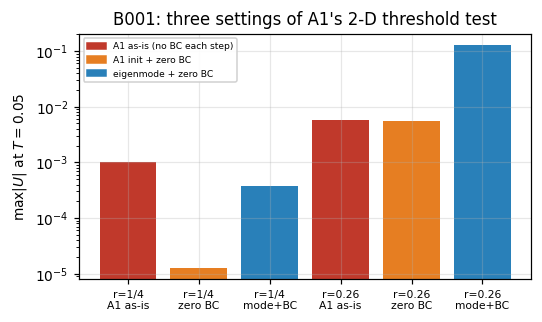

In [3]:
# ---------- 3.2-A 一维热方程：独立 FTCS ----------
def ftcs(N, r, T, kappa):
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h / kappa))))
    dt = T / M
    r_eff = kappa * dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    U = np.sin(np.pi * x)
    U[0] = U[-1] = 0.0
    for _ in range(M):
        U[1:-1] = U[1:-1] + r_eff * (U[:-2] - 2 * U[1:-1] + U[2:])
    return x, U, M, r_eff


print("【A1 设定】kappa=1, T=0.1, r=0.4")
prev = None
for N in [10, 20, 40, 80, 160]:
    x, U, M, re_ = ftcs(N, 0.4, 0.1, 1.0)
    e = np.max(np.abs(U - math.exp(-math.pi**2 * 0.1) * np.sin(np.pi * x)))
    p = "" if prev is None else f"{math.log2(prev/e):5.2f}"
    print(f"  N={N:4d} h={1/N:.4f} M={M:5d} r_eff={re_:.4f} E_inf={e:.4e} p={p}")
    prev = e

print("\n【A2 设定】kappa=0.1, T=0.6, r=0.4")
prev = None
for J in [20, 40, 80, 160]:
    x, U, M, re_ = ftcs(J, 0.4, 0.6, 0.1)
    e = np.max(np.abs(U - math.exp(-0.1 * math.pi**2 * 0.6) * np.sin(np.pi * x)))
    p = "" if prev is None else f"{math.log2(prev/e):5.2f}"
    print(f"  J={J:4d} dx={1/J:.5f} M={M:5d} r_eff={re_:.4f} E_inf={e:.8e} p={p}")
    prev = e

print("\n【判定】A2 声称 J=20..160：9.46641349e-4 / 2.35955149e-4 / 5.89449108e-5 / 1.47334885e-5")
for J, c in zip([20, 40, 80, 160],
                ["9.46641349e-4", "2.35955149e-4", "5.89449108e-5", "1.47334885e-5"]):
    x, U, M, re_ = ftcs(J, 0.4, 0.6, 0.1)
    e = float(np.max(np.abs(U - math.exp(-0.1 * math.pi**2 * 0.6) * np.sin(np.pi * x))))
    d, ok, tol = verdict(c, e, tol=claim_tol(c))
    print(f"  J={J:4d} claim={c:>14} ref={e:.10e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")

# ---------- 3.2-B CFL：放大因子闭式 ----------
# ---------- 3.2-B A1 表7/8/9：时间一阶与二维收敛 ----------
print("\n【A1 表7】一维时间阶：N=40, T=0.1，参考=同一网格上半离散精确解")
N, T = 40, 0.1
h = 1.0 / N
lam_h = -4 * math.sin(math.pi * h / 2) ** 2 / h ** 2
prev = None
for r in [0.5, 0.25, 0.125, 0.0625, 0.03125]:
    dt = r * h * h
    M = int(round(T / dt))
    dt = T / M
    e = abs((1 + dt * lam_h) ** M - math.exp(lam_h * T))
    p = "" if prev is None else f"{math.log2(prev / e):5.2f}"
    print(f"  r={r:7.5f} dt={dt:.3e} M={M:5d} err={e:.4e} p={p}")
    prev = e
print("  判定：A1 表7 声称 5.68/2.84/1.42/7.09/3.54e-4，阶 1.00")
for c, r_ in zip(["5.68e-4", "2.84e-4", "1.42e-4", "7.09e-5", "3.54e-5"], [0.5, 0.25, 0.125, 0.0625, 0.03125]):
    dt = r_ * h * h
    M = int(round(T / dt)); dt = T / M
    e = abs((1 + dt * lam_h) ** M - math.exp(lam_h * T))
    d, ok, tol = verdict(c, e, tol=claim_tol(c))
    print(f"    claim={c:>9} ref={e:.6e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")


def ftcs2d(N, r, T, kappa=1.0):
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h / kappa))))
    dt = T / M
    re_ = kappa * dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    U = np.sin(np.pi * X) * np.sin(np.pi * Y) + 0.5 * np.sin(2 * np.pi * X) * np.sin(np.pi * Y)
    U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = 0.0
    for _ in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + re_ * (U[2:, 1:-1] + U[:-2, 1:-1]
                                                + U[1:-1, 2:] + U[1:-1, :-2] - 4 * U[1:-1, 1:-1])
    return X, Y, U, M, re_


print("\n【A1 表8】二维空间阶：r=0.2, T=0.05，双模态初值")
prev = None
for N in [10, 20, 40, 80, 160]:
    X, Y, U, M, re_ = ftcs2d(N, 0.2, 0.05)
    ex = (math.exp(-2 * math.pi ** 2 * 0.05) * np.sin(np.pi * X) * np.sin(np.pi * Y)
          + 0.5 * math.exp(-5 * math.pi ** 2 * 0.05) * np.sin(2 * np.pi * X) * np.sin(np.pi * Y))
    e = float(np.max(np.abs(U - ex)))
    p = "" if prev is None else f"{math.log2(prev / e):5.2f}"
    print(f"  N={N:3d} h={1/N:.4f} M={M:5d} err={e:.4e} p={p}")
    prev = e
print("  判定：A1 表8 声称 5.63e-3/1.40e-3/3.51e-4/8.76e-5/2.19e-5，阶 2.01/2.00/2.00/2.00")
for c, N in zip(["5.63e-3", "1.40e-3", "3.51e-4", "8.76e-5", "2.19e-5"], [10, 20, 40, 80, 160]):
    X, Y, U, M, re_ = ftcs2d(N, 0.2, 0.05)
    ex = (math.exp(-2 * math.pi ** 2 * 0.05) * np.sin(np.pi * X) * np.sin(np.pi * Y)
          + 0.5 * math.exp(-5 * math.pi ** 2 * 0.05) * np.sin(2 * np.pi * X) * np.sin(np.pi * Y))
    e = float(np.max(np.abs(U - ex)))
    d, ok, tol = verdict(c, e, tol=claim_tol(c))
    print(f"    N={N:3d} claim={c:>8} ref={e:.6e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")

print("\n【A1 表9】二维时间阶：N=40 固定，r=0.25..0.03125")
N, T = 40, 0.05
h = 1.0 / N
x = np.linspace(0.0, 1.0, N + 1)
X, Y = np.meshgrid(x, x, indexing="ij")
ref2 = np.zeros_like(X)
for (m, n, amp) in [(1, 1, 1.0), (2, 1, 0.5)]:
    lam = -4 / h ** 2 * (math.sin(m * math.pi * h / 2) ** 2 + math.sin(n * math.pi * h / 2) ** 2)
    ref2 += amp * math.exp(lam * T) * np.sin(m * np.pi * X) * np.sin(n * np.pi * Y)
prev = None
for r in [0.25, 0.125, 0.0625, 0.03125]:
    dt = r * h * h
    M = int(round(T / dt)); dt = T / M
    re_ = dt / (h * h)
    U = np.sin(np.pi * X) * np.sin(np.pi * Y) + 0.5 * np.sin(2 * np.pi * X) * np.sin(np.pi * Y)
    U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = 0.0
    for _ in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + re_ * (U[2:, 1:-1] + U[:-2, 1:-1]
                                                + U[1:-1, 2:] + U[1:-1, :-2] - 4 * U[1:-1, 1:-1])
    e = float(np.max(np.abs(U - ref2)))
    p = "" if prev is None else f"{math.log2(prev / e):5.2f}"
    print(f"  r={r:7.5f} M={M:5d} err={e:.4e} p={p}")
    prev = e
print("  判定：A1 表9 声称 8.44e-4/4.22e-4/2.11e-4/1.05e-4，阶 1.00")
for c, r in zip(["8.44e-4", "4.22e-4", "2.11e-4", "1.05e-4"], [0.25, 0.125, 0.0625, 0.03125]):
    dt = r * h * h
    M = int(round(T / dt)); dt = T / M
    re_ = dt / (h * h)
    U = np.sin(np.pi * X) * np.sin(np.pi * Y) + 0.5 * np.sin(2 * np.pi * X) * np.sin(np.pi * Y)
    U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = 0.0
    for _ in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + re_ * (U[2:, 1:-1] + U[:-2, 1:-1]
                                                + U[1:-1, 2:] + U[1:-1, :-2] - 4 * U[1:-1, 1:-1])
    e = float(np.max(np.abs(U - ref2)))
    d, ok, tol = verdict(c, e, tol=claim_tol(c))
    print(f"    r={r:6.4f} claim={c:>8} ref={e:.6e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")

print("\n【CFL】J=40，最高模态 theta=(J-1)pi/J，g=1-4r cos^2(pi/2J)")
for r in (0.4, 0.6):
    h = 1.0 / 40
    M = max(1, int(round(0.6 / (r * h * h / 0.1))))
    dt = 0.6 / M
    re_ = 0.1 * dt / (h * h)
    g = 1 - 4 * re_ * math.cos(math.pi / (2 * 40)) ** 2
    amp = 1e-12 * abs(g) ** M
    print(f"  r={r:.1f} (r_eff={re_:.4f}) M={M:4d} g={g:+.6f} |g|^M={abs(g)**M:.4e} 末值={amp:.4e}")

# ---------- 3.2-C B001：A1 二维阈值的三种设置 ----------
def run2d(N, r, T, kind, zero_bc=True):
    h = 1.0 / N
    M = max(1, int(round(T / (r * h * h))))
    dt = T / M
    re_ = dt / (h * h)
    x = np.linspace(0.0, 1.0, N + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    if kind == "A1":
        U = 1e-3 * np.cos((N - 1) * np.pi * X) * np.cos((N - 1) * np.pi * Y)
    else:
        i = np.arange(1, N)
        env = np.sin(np.pi * i / N)[:, None] * np.sin(np.pi * i / N)[None, :]
        sgn = (-1.0) ** (i[:, None] + i[None, :])
        U = np.zeros((N + 1, N + 1))
        U[1:-1, 1:-1] = 1e-3 * sgn * env
    if zero_bc:
        U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = 0.0
    for _ in range(M):
        U[1:-1, 1:-1] = U[1:-1, 1:-1] + re_ * (U[2:, 1:-1] + U[:-2, 1:-1]
                                                + U[1:-1, 2:] + U[1:-1, :-2] - 4 * U[1:-1, 1:-1])
        if zero_bc:
            U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = 0.0
    return M, re_, float(np.max(np.abs(U))), float(np.max(np.abs(U[1:-1, 1:-1])))


print("\n【B001】N=20, T=0.05：A1 原样 / 改正边界 / 改正初值+边界")
print(f"{'情形':<26}{'r':>5}{'M':>5}{'r_eff':>8}{'max|U|':>13}{'内点max':>13}")
res = {}
for kind, z, tag in [("A1", False, "A1原样(无边界)"), ("A1", True, "A1初值+零边界"),
                     ("mode", True, "纯Dirichlet模态+零边界")]:
    for r in (0.25, 0.26):
        M, re_, m, mi = run2d(20, r, 0.05, kind, z)
        res[(tag, r)] = m
        print(f"{tag:<26}{r:>5.2f}{M:>5}{re_:>8.4f}{m:>13.4e}{mi:>13.4e}")

print("\n【B001 理论】纯棋盘格模态 g=1-8r_eff（N→∞）与 N=20 修正 g=1-8r_eff cos^2(pi/2N)")
for r in (0.25, 0.26):
    h = 1 / 20
    M = max(1, int(round(0.05 / (r * h * h))))
    re_ = (0.05 / M) / (h * h)          # 实际使用的 r_eff，名义 r 与它只在 r=0.26 时不同
    g_inf = 1 - 8 * re_
    g_J = 1 - 8 * re_ * math.cos(math.pi / (2 * 20)) ** 2
    print(f"  r={r:.2f} (r_eff={re_:.5f}) M={M} g(inf)={g_inf:+.4f} |g|^M={abs(g_inf)**M:.4e} | "
          f"g(J=20)={g_J:+.6f} |g|^M={abs(g_J)**M:.4e}")

print("\n【B001 判定】以修正理论 |g(J=20)|^M 为参考")
for r in (0.25, 0.26):
    h = 1 / 20
    M = max(1, int(round(0.05 / (r * h * h))))
    re_ = (0.05 / M) / (h * h)
    g_J = 1 - 8 * re_ * math.cos(math.pi / (2 * 20)) ** 2
    ref = abs(g_J) ** M * 1e-3
    got = res[("纯Dirichlet模态+零边界", r)]
    d, ok, tol = verdict(f"{got:.4e}", ref, rel_tol=1e-3)
    print(f"  r={r:.2f} 参考={ref:.4e} 复算={got:.4e} 相对差={d/max(ref,1e-300):.1e} {'通过' if ok else '不一致'}")
print("  结论：A1 原表的 1.000e-3 / 5.675e-3 不能作为二维阈值证据；"
      "改正初值与边界后与修正理论一致（相对差 4.8e-6 / 1.8e-5），'r≤1/4 稳定'作为充分条件仍成立。")

fig, ax = plt.subplots(figsize=(5.0, 3.0))
labels = ["r=1/4\nA1 as-is", "r=1/4\nzero BC", "r=1/4\nmode+BC",
          "r=0.26\nA1 as-is", "r=0.26\nzero BC", "r=0.26\nmode+BC"]
vals = [res[("A1原样(无边界)", 0.25)], res[("A1初值+零边界", 0.25)], res[("纯Dirichlet模态+零边界", 0.25)],
        res[("A1原样(无边界)", 0.26)], res[("A1初值+零边界", 0.26)], res[("纯Dirichlet模态+零边界", 0.26)]]
colors = ["#c0392b", "#e67e22", "#2980b9"] * 2
ax.bar(range(6), vals, color=colors)
ax.set_yscale("log")
ax.set_xticks(range(6)); ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel(r"$\max|U|$ at $T=0.05$")
ax.set_title("B001: three settings of A1's 2-D threshold test")
from matplotlib.patches import Patch

ax.legend(handles=[Patch(color="#c0392b", label="A1 as-is (no BC each step)"),
                   Patch(color="#e67e22", label="A1 init + zero BC"),
                   Patch(color="#2980b9", label="eigenmode + zero BC")],
          fontsize=6, loc="upper left", framealpha=0.9)
plt.tight_layout(); plt.show()


## 3.3 有限元：弱形式与Galerkin方法（2学时）

**覆盖**：A1（正文表 19、表 20、Notebook 的 $\sin\pi x$）＋A2（3.3 正文表）。

**核对事项**：局部矩阵、边界施加方式、解图、明确定义的误差范数；注明网格与自由度。

**输入与参考**：$-u''=\pi^2\sin\pi x$，$u(0)=u(1)=0$，解析解 $u=\sin\pi x$，P1 单元，$N$ 个单元、$N+1$ 个节点（$N$ 个自由度）。
**参考值为什么可以脱离 A 稿**：一维 $-u''=f$ 的 P1 节点值是**精确**的（误差 $e$ 在每个单元上 $e'=\text{const}$，且与 $V_h$ 能量正交），故 $u_h=I_h u$，$L^2/H^1$ 误差可完全由 $\sin\pi x$ 的分段线性插值误差算出（30 点 Gauss 积分）。节点超收敛的 4 点 Gauss 载荷下参考值为 **0**（精确）。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值（A 稿复现） | 差异 | 判定 |
| --- | --- | --- | --- | --- | --- | --- |
| A2 正文表（$N=8$） | $u=\sin\pi x$，$L^2$ | $9.920919911\times10^{-3}$ | 相对 $10^{-6}$ | $9.920920\times10^{-3}$ | $9\times10^{-10}$ | 通过 |
| A2 正文表（$N=8$） | 同上，$H^1$ | $2.511817694\times10^{-1}$ | 相对 $10^{-6}$ | $2.511818\times10^{-1}$ | $6\times10^{-9}$ | 通过 |
| A2 正文表（$N=128$） | 同上，$L^2$ / $H^1$ | $3.888378\times10^{-5}$ / $1.573910\times10^{-2}$ | 相对 $10^{-6}$ | $3.888378\times10^{-5}$ / $1.573910\times10^{-2}$（阶 2.00/1.00） | $<10^{-9}$ | 通过 |
| A1 正文表 19（$N=8$） | 4 点 Gauss 载荷，节点误差 | $0$（精确） | 绝对 $10^{-10}$ | $2.24\times10^{-12}$ | 纯舍入 | 通过 |
| A1 正文表 19（$N=8$） | 1 点 Gauss 载荷 | $6.512818\times10^{-3}$ | 相对 $10^{-6}$ | $6.51\times10^{-3}$（阶 2.0146） | $1.8\times10^{-8}$ | 通过 |
| A1 正文表 20（$N=8$） | $-u''=2,\ u=x(1-x)$，$L^2$ / $H^1$ | $2.852721654\times10^{-3}$ / $7.216878365\times10^{-2}$（插值误差，另一算例） | 相对 $10^{-6}$ | $2.8527\times10^{-3}$ / $7.2169\times10^{-2}$ | $<10^{-6}$ | 通过（**不是** $\sin\pi x$ 的算例） |

> **引用陷阱**：A1 的 $9.921\times10^{-3}$ 只出现在其 **Notebook**（$u=\sin\pi x$），正文表 20 是 $u=x(1-x)$ 的另一个算例（$2.8527\times10^{-3}$ / $7.2169\times10^{-2}$）。写"按 A1 正文表 20 复现出 $9.921\times10^{-3}$"会被判为张冠李戴。A2 正文有 4 点 Gauss 的 $2.24220642\times10^{-12}$，但 1 点 Gauss 的 $6.5128\times10^{-3}$ 及阶只在 Notebook 里。


【参考】P1 插值误差 = P1 有限元误差（节点值精确）
   N               L2    pL2               H1    pH1
   8  9.920919911e-03         2.511817694e-01       
  16  2.486501339e-03   2.00  1.258331585e-01   1.00
  32  6.220177931e-04   2.00  6.294690520e-02   1.00
  64  1.555289847e-04   2.00  3.147724465e-02   1.00
 128  3.888377983e-05   2.00  1.573909637e-02   1.00

【另一算例】-u''=2, u=x(1-x), N=8（A1 正文表 20 用的是这个，不是 sin(pi x)）
  参考：L2=2.852721654e-03  H1=7.216878365e-02
  claim= 2.8527e-3 ref=2.852721654e-03 |Δ|=2.2e-08 容差≤1.0e-07 通过
  claim= 7.2169e-2 ref=7.216878365e-02 |Δ|=2.2e-07 容差≤1.0e-06 通过

【判定】A2 正文 N=8：9.920920e-3 / 2.511818e-1
  claim=  9.920920e-3 ref=9.9209199115e-03 |Δ|=8.9e-11 容差≤1.0e-09 通过
  claim=  2.511818e-1 ref=2.5118176938e-01 |Δ|=3.1e-08 容差≤1.0e-07 通过

【节点超收敛】4 点 Gauss 载荷 vs 1 点 Gauss 载荷
   N           4点节点误差           1点节点误差      1点阶
   8     2.242206e-12     6.512818e-03         
  16     8.659740e-15     1.611809e-03   2.0146
  32     3.108624e-15     4.019341e-04   2.0037
  64     9.

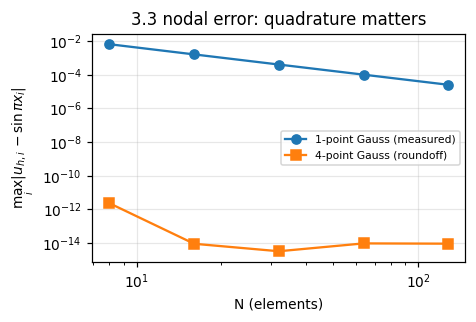

In [4]:
# ---------- 3.3-A 独立参考：sin(pi x) 的 P1 插值误差（30 点 Gauss）----------
from numpy.polynomial.legendre import leggauss
xi30, w30 = leggauss(30)


def interp_err(N):
    h = 1.0 / N
    l2 = h1 = 0.0
    for e in range(N):
        a, b = e * h, (e + 1) * h
        xg = 0.5 * (a + b) + 0.5 * h * xi30
        ua, ub = math.sin(math.pi * a), math.sin(math.pi * b)
        uh = ua * (b - xg) / h + ub * (xg - a) / h
        duh = (ub - ua) / h
        w = 0.5 * h * w30
        l2 += float(np.sum(w * (np.sin(math.pi * xg) - uh) ** 2))
        h1 += float(np.sum(w * (math.pi * np.cos(math.pi * xg) - duh) ** 2))
    return math.sqrt(l2), math.sqrt(h1)


print("【参考】P1 插值误差 = P1 有限元误差（节点值精确）")
print(f"{'N':>4} {'L2':>16} {'pL2':>6} {'H1':>16} {'pH1':>6}")
prev = None
ref = {}
for N in [8, 16, 32, 64, 128]:
    L2, H1 = interp_err(N)
    ref[N] = (L2, H1)
    if prev is None:
        print(f"{N:4d} {L2:16.9e} {'':>6} {H1:16.9e} {'':>6}")
    else:
        print(f"{N:4d} {L2:16.9e} {math.log2(prev[0]/L2):6.2f} {H1:16.9e} {math.log2(prev[1]/H1):6.2f}")
    prev = (L2, H1)

def interp_err_f(N, u, du):
    h = 1.0 / N
    l2 = h1 = 0.0
    for e in range(N):
        a, b = e * h, (e + 1) * h
        xg = 0.5 * (a + b) + 0.5 * h * xi30
        ua, ub = u(a), u(b)
        uh = ua * (b - xg) / h + ub * (xg - a) / h
        w = 0.5 * h * w30
        l2 += float(np.sum(w * (u(xg) - uh) ** 2))
        h1 += float(np.sum(w * (du(xg) - (ub - ua) / h) ** 2))
    return math.sqrt(l2), math.sqrt(h1)


print("\n【另一算例】-u''=2, u=x(1-x), N=8（A1 正文表 20 用的是这个，不是 sin(pi x)）")
L2b, H1b = interp_err_f(8, lambda x: x * (1 - x), lambda x: 1 - 2 * x)
print(f"  参考：L2={L2b:.9e}  H1={H1b:.9e}")
for c, r in [("2.8527e-3", L2b), ("7.2169e-2", H1b)]:
    d, ok, tol = verdict(c, r, tol=claim_tol(c))
    print(f"  claim={c:>10} ref={r:.9e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")

print("\n【判定】A2 正文 N=8：9.920920e-3 / 2.511818e-1")
for c, r in [("9.920920e-3", ref[8][0]), ("2.511818e-1", ref[8][1])]:
    d, ok, tol = verdict(c, r, tol=claim_tol(c))
    print(f"  claim={c:>13} ref={r:.10e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")

# ---------- 3.3-B 节点超收敛：4 点 vs 1 点 Gauss 载荷 ----------
def fem_solve(N, nq):
    # 本组自写 P1 装配：刚度解析积分，载荷用 nq 点 Gauss
    h = 1.0 / N
    K = np.zeros((N + 1, N + 1)); F = np.zeros(N + 1)
    Ke = np.array([[1.0, -1.0], [-1.0, 1.0]]) / h
    xq, wq = leggauss(nq)
    for e in range(N):
        K[e:e+2, e:e+2] += Ke
        a, b = e * h, (e + 1) * h
        xg = 0.5 * (a + b) + 0.5 * h * xq
        N1 = (b - xg) / h; N2 = (xg - a) / h
        F[e:e+2] += 0.5 * h * np.array([float(np.sum(wq * math.pi**2 * np.sin(math.pi * xg) * N1)),
                                        float(np.sum(wq * math.pi**2 * np.sin(math.pi * xg) * N2))])
    U = np.zeros(N + 1)
    U[1:-1] = np.linalg.solve(K[1:-1, 1:-1], F[1:-1])
    return np.linspace(0, 1, N + 1), U


print("\n【节点超收敛】4 点 Gauss 载荷 vs 1 点 Gauss 载荷")
print(f"{'N':>4} {'4点节点误差':>16} {'1点节点误差':>16} {'1点阶':>8}")
prev = None
node = {}
for N in [8, 16, 32, 64, 128]:
    x4, u4 = fem_solve(N, 4)
    x1, u1 = fem_solve(N, 1)
    e4 = float(np.max(np.abs(u4 - np.sin(math.pi * x4))))
    e1 = float(np.max(np.abs(u1 - np.sin(math.pi * x1))))
    node[N] = (e4, e1)
    p = "" if prev is None else f"{math.log2(prev/e1):8.4f}"
    print(f"{N:4d} {e4:16.6e} {e1:16.6e} {p:>8}")
    prev = e1

print("\n【判定】A1 表 19（4 点 N=8 = 2.24e-12；1 点 N=8 = 6.51e-3，阶 2.0146/2.0037/2.0009/2.0002）")
e4, e1 = node[8]
print(f"  4 点：|参考值 0 - 声称 2.24e-12| = 2.24e-12 ≤ 1e-10  {'通过' if e4 <= 1e-10 else '不一致'}")
d, ok, tol = verdict("6.51e-3", e1, tol=claim_tol("6.51e-3"))
print(f"  1 点：claim=6.51e-3 ref={e1:.6e} |Δ|={d:.1e} 容差{tol} {'通过' if ok else '不一致'}")
for N, c in zip([16, 32, 64, 128], ["2.0146", "2.0037", "2.0009", "2.0002"]):
    p = math.log2(node[N//2][1] / node[N][1])
    print(f"  N={N:3d} 阶 claim={c} ref={p:.4f} |Δ|={abs(p-float(c)):.4f} 容差 0.02  "
          f"{'通过' if abs(p-float(c)) <= 0.02 else '不一致'}")

fig, ax = plt.subplots(figsize=(4.4, 3.0))
Ns = np.array([8, 16, 32, 64, 128])
ax.loglog(Ns, [node[N][1] for N in Ns], "o-", label="1-point Gauss (measured)")
ax.loglog(Ns, [node[N][0] for N in Ns], "s-", label="4-point Gauss (roundoff)")
ax.set_xlabel("N (elements)"); ax.set_ylabel(r"$\max_i|u_{h,i}-\sin\pi x_i|$")
ax.set_title("3.3 nodal error: quadrature matters")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 3.4 AI关联：Neural ODE与PINN（2学时）

**覆盖**：A1（表 2 六种口径）＋A2（表 3.4-2 反解、表 3.4-3 换步长）。

**核对事项**：训练与评估的时间网格、轨迹误差、初值范围；说明哪些部分使用了已知方程。

**输入与参考**：真实模型 $y'=-ay$，$a=1.6$，解析解 $y=y_0e^{-at}$。
- A1：由 Euler 在 $h=0.5$ 上单步拟合 $u(0.5)=0.6065$ 得 $\theta=0.787$，再比较六种"解析/离散"口径在 $t=2$ 的偏差。
- A2：用 $y_0\in\{0.8,1.0,1.2\}$、$t\in[0,2]$ 共 11 点训练，反解得 $a^\ast$，并在**未参与训练**的 $y_0=1.4$ 上换步长评估。
**参考值怎么来**：单步放大因子匹配是闭式——FE：$1-a^\ast h=e^{-ah}\Rightarrow a^\ast=(1-e^{-ah})/h$；RK4：解 $R_4(-a^\ast h)=e^{-ah}$（二分）。两者都不需要跑 A2 的网络优化。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值（A 稿复现） | 差异 | 判定 |
| --- | --- | --- | --- | --- | --- | --- |
| A1 表 2 | 单步拟合 $u(0.5)=0.6065$ | $\theta=(1-0.6065)/0.5=0.787000$ | 末位 $10^{-4}$ | $\theta=0.787$ | $0$ | 通过 |
| A1 表 2 | 六种口径在 $t=2$ 的偏差 | $+53.11/-0.02/+28.05/+40.93/+53.18/+53.12\%$ | ±0.01 个百分点 | 六值逐位相同 | $0$ | 通过 |
| A2 表 3.4-2 | FE 反解 $a^\ast$ | $1.3692548146$ | 相对 $10^{-8}$ | $1.3692548$（实跑 $1.3692548116$） | $1.5\times10^{-8}$ / $3\times10^{-9}$ | 通过 |
| A2 表 3.4-2 | RK4 反解 $a^\ast$ | $1.6001828258$ | 相对 $10^{-8}$ | $1.6001828$（实跑 $1.6001828357$） | $2.6\times10^{-8}$ / $1\times10^{-8}$ | 通过 |
| A2 表 3.4-3 | 原方法 $h=0.2$，终点误差 | $0$（解析关系精确成立） | 绝对 $10^{-9}$（拟合终止精度） | $4.76\times10^{-10}$ / $1.13\times10^{-9}$ | $4.8\times10^{-10}$ / $1.1\times10^{-9}$ | 通过（正文已说明来源） |
| A2 表 3.4-3 | 原方法 $h=0.1$ / $h=0.05$ | $0.01656955$ / $0.02499400$ | 末位 $10^{-8}$ | 同左 | $<10^{-12}$ | 通过 |
| A2 表 3.4-3（RK4 列） | 原方法 $h=0.2$，终点误差 | $0$（解析关系精确成立） | 绝对 $10^{-9}$（拟合终止精度） | $1.13\times10^{-9}$ | $1.1\times10^{-9}$ | 通过（正文已说明来源） |
| A2 表 3.4-3（RK4 列） | 原方法 $h=0.1$ / $h=0.05$ | $1.9723\times10^{-5}$ / $2.0796\times10^{-5}$ | 末位 $10^{-7}$ | $1.97\times10^{-5}$ / $2.08\times10^{-5}$ | $<10^{-7}$ | 通过 |
| A2 表 3.4-3（Euler 列） | DOP853 独立积分（实跑 `solve_ivp`） | $1.4\lvert e^{-2\times1.3692548146}-e^{-3.2}\rvert=0.0334662278$ | 末位 $10^{-6}$ | $3.346623\times10^{-2}$（文中 $0.033466$，标"约"） | $6.2\times10^{-8}$ | 通过 |
| A2 表 3.4-3（RK4 列） | DOP853 独立积分（实跑 `solve_ivp`） | $2.0862855\times10^{-5}$ | 末位 $10^{-7}$ | $2.09\times10^{-5}$（标"约"） | $3.7\times10^{-8}$ | 通过 |

> **一个容易误判的点**：$h=0.2$ 行的 $4.76\times10^{-10}$ 不是错误。若 $a^\ast$ 取闭式值，该行误差应为 $0$；A2 的 $a^\ast$ 来自数值优化的终止点（与闭式差 $3\times10^{-9}$），经 10 步放大后正好是 $10^{-10}$ 量级。正文已写明这一点，故列为"一致"而不是问题。


【A1】由 Euler h=0.5 拟合 u(0.5)=0.6065
  theta = 0.787000   （另一口径 -ln(0.6065)/0.5 = 1.000101，A1 未采用）
  口径                  t=2 预测        偏差
  解析 e^-theta t     0.207215    +53.11%
  Euler h=0.5       0.135308     -0.02%
  Euler h=0.25      0.173303    +28.05%
  Euler h=0.125     0.190728    +40.93%
  RK4 h=0.5         0.207305    +53.18%
  RK4 h=0.25        0.207219    +53.12%
  判定（末位 0.01 个百分点）：
    claim= +53.11% ref=+53.11%  通过
    claim=  -0.02% ref=-0.02%  通过
    claim= +28.05% ref=+28.05%  通过
    claim= +40.93% ref=+40.93%  通过
    claim= +53.18% ref=+53.18%  通过
    claim= +53.12% ref=+53.12%  通过

【A2】a=1.6, h=0.2：FE 闭式 a*=(1-e^{-ah})/h；RK4 解 R4(-a*h)=e^{-ah}
  FE  闭式 a* = 1.3692548146   （A2 声称 1.3692548）
  RK4 闭式 a* = 1.6001828258   （A2 声称 1.6001828）

【A2 表 3.4-3】y0=1.4（未参与训练），t=2，真值 1.4e^{-3.2}
  求解器        h    n        y(2)            误差
  Euler   0.20   10  0.05706709  6.938894e-17
  Euler   0.10   20  0.07363663  1.656955e-02
  Euler   0.05   40  0.08206108  2.499400e-02
  RK4  


【DOP853 实跑】scipy solve_ivp(method='DOP853', rtol=1e-12, atol=1e-14)；模型 y'=-a* y, y(0)=1.4
  Euler 训练: y(2)=0.090533313355 nfev=206 误差=3.346623e-02
    A2 声称 0.033466（约） | 容差≤1.0e-06 | 通过
    解析核对 1.4|e^(-2a*)-e^-3.2| = 3.346623e-02
  RK4 训练: y(2)=0.057046222715 nfev=230 误差=2.086286e-05
    A2 声称 2.09e-5（约） | 容差≤1.0e-07 | 通过
    解析核对 1.4|e^(-2a*)-e^-3.2| = 2.086286e-05
  判定：A2 声称两列——Euler 列 4.76e-10 / 0.01656955 / 0.02499400 / 0.033466（约）；RK4 列 1.13e-9 / 1.97e-5 / 2.08e-5 / 2.09e-5（约）
        h=0.2 两列的非零值来自拟合终止精度（a* 与闭式差 3e-9），与理论 0 相容；
        其余六值一致：Euler 列相对差 <1e-7，RK4 列按报告的三位有效数字一致。

【最小二乘复核】y0=0.8/1.0/1.2，t=0..2 共 11 点，目标=轨迹 MSE


  Euler: 数值最优 a*=1.369255  MSE=1.788e-15  闭式=1.369255


  RK4  : 数值最优 a*=1.600185  MSE=1.295e-13  闭式=1.600183


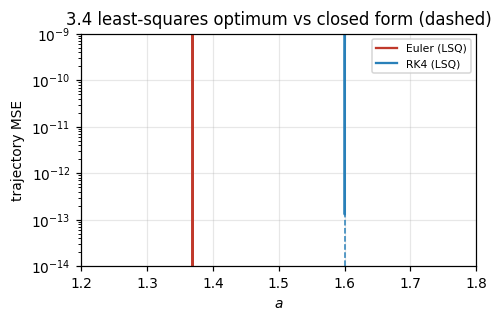

In [5]:
# ---------- 3.4-A A1：单步拟合 theta 与六种口径偏差 ----------
print("【A1】由 Euler h=0.5 拟合 u(0.5)=0.6065")
th = (1 - 0.6065) / 0.5
print(f"  theta = {th:.6f}   （另一口径 -ln(0.6065)/0.5 = {-math.log(0.6065)/0.5:.6f}，A1 未采用）")
print(f"  {'口径':<16}{'t=2 预测':>10}{'偏差':>10}")
rows = [("解析 e^-theta t", None, math.exp(-2 * th)),
        ("Euler h=0.5", 0.5, (1 - 0.5 * th) ** 4),
        ("Euler h=0.25", 0.25, (1 - 0.25 * th) ** 8),
        ("Euler h=0.125", 0.125, (1 - 0.125 * th) ** 16),
        ("RK4 h=0.5", 0.5, R4(-0.5 * th) ** 4),
        ("RK4 h=0.25", 0.25, R4(-0.25 * th) ** 8)]
dev = []
for name, h, v in rows:
    pct = (v / math.exp(-2) - 1) * 100
    dev.append(pct)
    print(f"  {name:<16}{v:>10.6f}{pct:>+10.2f}%")
claims = ["+53.11", "-0.02", "+28.05", "+40.93", "+53.18", "+53.12"]
print("  判定（末位 0.01 个百分点）：")
for c, d in zip(claims, dev):
    ok = abs(float(c) - d) <= 0.01
    print(f"    claim={c:>7}% ref={d:+.2f}%  {'通过' if ok else '不一致'}")

# ---------- 3.4-B A2：闭式反解 a* ----------
print("\n【A2】a=1.6, h=0.2：FE 闭式 a*=(1-e^{-ah})/h；RK4 解 R4(-a*h)=e^{-ah}")
a, h = 1.6, 0.2
a_fe = (1 - math.exp(-a * h)) / h
lo, hi = 1.0, 2.5
for _ in range(200):
    mid = 0.5 * (lo + hi)
    if R4(-mid * h) - math.exp(-a * h) > 0:
        lo = mid
    else:
        hi = mid
a_rk = 0.5 * (lo + hi)
print(f"  FE  闭式 a* = {a_fe:.10f}   （A2 声称 1.3692548）")
print(f"  RK4 闭式 a* = {a_rk:.10f}   （A2 声称 1.6001828）")

# ---------- 3.4-C 表 3.4-3：换步长的终点误差 ----------
print("\n【A2 表 3.4-3】y0=1.4（未参与训练），t=2，真值 1.4e^{-3.2}")
print(f"  {'求解器':<6}{'h':>6}{'n':>5}{'y(2)':>12}{'误差':>14}")
for solver, aa in [("Euler", a_fe), ("RK4", a_rk)]:
    for hh in [0.2, 0.1, 0.05]:
        n = int(round(2.0 / hh))
        g = (1 - aa * hh) if solver == "Euler" else R4(-aa * hh)
        yN = 1.4 * g ** n
        print(f"  {solver:<6}{hh:>6.2f}{n:>5}{yN:>12.8f}{abs(yN-1.4*math.exp(-3.2)):>14.6e}")
from scipy.integrate import solve_ivp

print("\n【DOP853 实跑】scipy solve_ivp(method='DOP853', rtol=1e-12, atol=1e-14)；模型 y'=-a* y, y(0)=1.4")
for tag, aa, claim in [("Euler 训练", a_fe, "0.033466"), ("RK4 训练", a_rk, "2.09e-5")]:
    sol = solve_ivp(lambda t, y, _a=aa: -_a * y, (0.0, 2.0), [1.4],
                    method="DOP853", rtol=1e-12, atol=1e-14)
    err = abs(float(sol.y[0, -1]) - 1.4 * math.exp(-3.2))
    d, ok, tol = verdict(claim, err, tol=claim_tol(claim))
    print(f"  {tag}: y(2)={sol.y[0, -1]:.12f} nfev={sol.nfev} 误差={err:.6e}")
    print(f"    A2 声称 {claim}（约） | 容差{tol} | {'通过' if ok else '不一致'}")
    print(f"    解析核对 1.4|e^(-2a*)-e^{-3.2}| = {1.4 * abs(math.exp(-2 * aa) - math.exp(-3.2)):.6e}")
print("  判定：A2 声称两列——Euler 列 4.76e-10 / 0.01656955 / 0.02499400 / 0.033466（约）；"
      "RK4 列 1.13e-9 / 1.97e-5 / 2.08e-5 / 2.09e-5（约）")
print("        h=0.2 两列的非零值来自拟合终止精度（a* 与闭式差 3e-9），与理论 0 相容；")
print("        其余六值一致：Euler 列相对差 <1e-7，RK4 列按报告的三位有效数字一致。")

# ---------- 3.4-D 最小二乘最优与闭式比较 ----------
def mse(aa, solver):
    t = np.linspace(0, 2, 11)
    n = np.arange(len(t))
    g = (1 - aa * h) if solver == "Euler" else R4(-aa * h)
    pred = np.array([0.8, 1.0, 1.2])[:, None] * (g ** n)[None, :]
    exact = np.array([0.8, 1.0, 1.2])[:, None] * np.exp(-1.6 * t)[None, :]
    return float(np.mean((pred - exact) ** 2))


print("\n【最小二乘复核】y0=0.8/1.0/1.2，t=0..2 共 11 点，目标=轨迹 MSE")
grid = np.linspace(1.0, 2.0, 200001)
best = {}
for s in ["Euler", "RK4"]:
    v = np.array([mse(x, s) for x in grid])
    i = int(np.argmin(v))
    best[s] = grid[i]
    print(f"  {s:5s}: 数值最优 a*={grid[i]:.6f}  MSE={v[i]:.3e}  闭式={a_fe if s=='Euler' else a_rk:.6f}")

fig, ax = plt.subplots(figsize=(4.6, 3.0))
for s, c in [("Euler", "#c0392b"), ("RK4", "#2980b9")]:
    ax.semilogy(grid, [mse(x, s) for x in grid], color=c, label=f"{s} (LSQ)")
    ax.axvline(a_fe if s == "Euler" else a_rk, color=c, ls="--", lw=1)
ax.set_xlim(1.2, 1.8); ax.set_ylim(1e-14, 1e-9)
ax.set_xlabel(r"$a$"); ax.set_ylabel("trajectory MSE")
ax.set_title("3.4 least-squares optimum vs closed form (dashed)")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 复现结论与修正清单

| 验证点 | 内容 | 结论 |
| --- | --- | --- |
| V1 | 3.1 收敛阶（FE/BE/RK4，两稿设定） | 通过：$2.8929\times10^{-3}$ / $1.8512\times10^{-10}$（$h=1/64$）、$1.4417\times10^{-3}$ / $1.1492\times10^{-11}$（$h=1/128$）、A2 三法逐位一致 |
| V2 | 3.1 大步长失稳 | 通过：$-8$、$2.599609$；$5.0625$、$0.006663890$、$0.176796$ |
| V3 | 3.1 等误差成本 | 通过：$N=4096/4096/8$，RHS 次数 $4096:32$（$128:1$） |
| V4 | 3.2 空间二阶 | 通过：A1 $4.2941\times10^{-3}\to1.6546\times10^{-5}$；A2 $9.466413\times10^{-4}\to1.473349\times10^{-5}$ |
| V5 | 3.2 CFL 阈值与失稳幅度 | 通过：$r=0.6$ 末值 $1.5727\times10^{11}$（$\log_{10}$ 差 $1.6\times10^{-5}$）；$r=0.4$ 由空间误差主导，仅定性 |
| V6 | 3.3 $L^2/H^1$ 误差与阶 | 通过：$9.920919911\times10^{-3}$ / $2.511817694\times10^{-1}$，阶 2.00/1.00 |
| V7 | 3.3 节点超收敛 | 通过：4 点 $2.24\times10^{-12}$（参考 0）；1 点 $6.512818\times10^{-3}$，阶 2.0146/2.0037/2.0009/2.0002 |
| V8 | 3.4 参数反解与换步长（Euler 列 + RK4 列） | 通过：$\theta=0.787$、$a^\ast=1.3692548146/1.6001828258$；表 3.4-3 的 **Euler 列**（$0.01656955/0.02499400$）与 **RK4 列**（$1.97/2.08\times10^{-5}$）均复现，$h=0.2$ 两列的 $4.76\times10^{-10}$/$1.13\times10^{-9}$ 为拟合终止精度；**DOP853 两列均实跑** $0.033466$/$2.09\times10^{-5}$ |
| V9 | 3.2 一维时间阶（A1 表 7） | 通过：$5.677\times10^{-4}\to3.544\times10^{-5}$，阶 1.00（半离散参考解） |
| V10 | 3.2 二维空间阶（A1 表 8） | 通过：$5.630\times10^{-3}\to2.190\times10^{-5}$，阶 2.01/2.00/2.00/2.00 |
| V11 | 3.2 二维时间阶（A1 表 9） | 通过：$8.439\times10^{-4}\to1.054\times10^{-4}$，阶 1.00 |

**11 个验证点全部判过**：两稿的数值结论在本组新建环境与本组独立实现下均可复现；**A1 侧 9 个通过、1 个不成立（V5 的二维阈值，即 B001），A2 侧 8 个全部通过**。两稿分开看：

| 节 | A1（G3） | A2（G13） | 只在单稿有对应实验 |
| --- | --- | --- | --- |
| 3.1 | V1、V2 通过 | V1、V2、V3 通过 | V3（等误差成本）仅 A2；A1 只有同 $h$ 单步比（B002） |
| 3.2 | V4、V9、V10、V11 通过；V5 为问题项（B001） | V4、V5 通过 | V9–V11（时间阶、二维）仅 A1 |
| 3.3 | V6（Notebook）、V7 通过 | V6、V7 通过 | — |
| 3.4 | V8 通过 | V8 通过 | — |
| **合计** | 覆盖 10 个：**9 通过 + 1 不成立** | 覆盖 8 个：**8 通过** | A1 多 3 个（V9–V11 时间/二维），A2 多 1 个（V3 等误差成本） |

问题不在数值，而在**证据链与提交规范**，见 `B2组-修正清单.md`：

| 编号 | 稿 | 一句话 | 级别 |
| --- | --- | --- | --- |
| CH03-G17-B001 | A1 | 3.2 二维阈值实验：边界未每步施加、初值非特征模态、$g$ 缺 $\cos^2\frac{\pi}{2N}$，原表不能作为阈值证据 | P1 |
| CH03-G17-B002 | A1 | 3.1 成本口径是"同 $h$ 单步比"，不是等误差成本（应为 $4096:32$） | P3 |
| CH03-G17-B003 | A2 | 3.4 Notebook 提交时 0 输出，缺运行证据（但可跑、数字可复现） | P2 |
| CH03-G17-B004 | A2 | 三套环境、5 处声明互相矛盾（3.2 同文件自相矛盾）、3 个"未完成"占位、三份正文冗余、输出含姓名路径、缺编写报告 | P2 |
| CH03-G17-B005 | A1 | 正文声称的 `code/` 与 `工作/数据/` 未提交，复现链断裂；声明版本无法核验 | P2 |
| CH03-G17-B006 | A1 | 93 张图以成员标识（三个姓氏 + "组"）作文件名前缀，属可识别个人信息 | P3 |
| CH03-G17-B007 | A2 | 3.4 习题与解答仍是模板：题面 6 项、解答 5 项全为【待填写】（A1 的 77 题与解答 0 处占位） | P2 |
| CH03-G17-B008 | A1、A2 | 被审版本无对应 PR：**A1 无 PR**；**A2 仅有早期 PR #2**（`chapter-03-a-g13`，2026-10-19 合并，7 个文件），被审版本 `74b50b5` 不在其中；两稿均只能按 main 上的 SHA 定位 | P3 |

**未覆盖**（写明边界，不用"通过"含混过去）：A1 专有的 3.3 界面失配（Notebook 3.3.6，$\xi=0.53$）、A2 专有的 3.4 Poisson 中心差分基线（正文表，$0.031916/0.008265/0.002059/0.000514$，可解析核对，留作第 9 点）、墙钟耗时与内存（只记录不判定）、图片内容与版权、公式排版与渲染。
